In [1]:
from telescope import *
from spectrograph import *
from detector import *
from spectralmodels import Sky, get_list_of_stellar_models, get_stellar_spectrum
from etc.etc import simulate_1D_spectrum, simulate_2D_spectrum, SpecETC

from pathlib import Path
from astropy.table import Table
import numpy as np
from matplotlib import pyplot as plt

In [2]:
models = get_list_of_stellar_models(verbose=True)
sptype = 'G5V'
mag = 14
star = get_stellar_spectrum(sptype=sptype, mag=mag)
sky = Sky(seeing=3.0*u.arcsec, mag=19)

O ['O5V', 'O8III', 'O9V']
B ['B8V', 'B6IV', 'B1V', 'B8I', 'B3V', 'B5II', 'B5III', 'B2II', 'B9III', 'B5-7V', 'B1-2III', 'B2IV', 'B0V', 'B5I', 'B0I']
A ['A3V', 'A2V', 'A0I', 'A5V', 'A4-7IV', 'A0III', 'A5III', 'A0IV', 'A0V']
F ['F2II', 'F0-2IV', 'F0V', 'F8I', 'F0III', 'F5IV', 'F2V', 'F8IV', 'F0I', 'F8V', 'F5V', 'F5III', 'F0II', 'F5I']
G ['G8IV', 'G5V', 'G8III', 'G5III', 'G2IV', 'G8I', 'G5I', 'G5IV', 'G8V', 'G2V', 'G5II', 'G0I', 'G0IV', 'G0III', 'G0V']
K ['K2V', 'K4I', 'K0-1II', 'K7V', 'K2I', 'K5V', 'K3IV', 'K0IV', 'K3-4II', 'K0III', 'K1IV', 'K0V', 'K5III', 'K3III']
M ['M10III', 'M0V', 'M4V', 'M5III', 'M5V', 'M2V', 'M3II', 'M0III', 'M2I']


In [3]:
IMX183.exptime = 600*u.second
IMX183.set_binning(3)

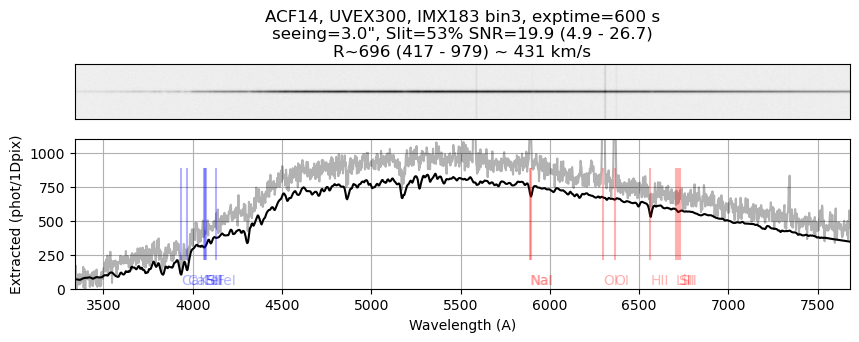

In [4]:
im, spec, var = SpecETC(star, sky, ACF14, UVEX300, IMX183, plot=True)

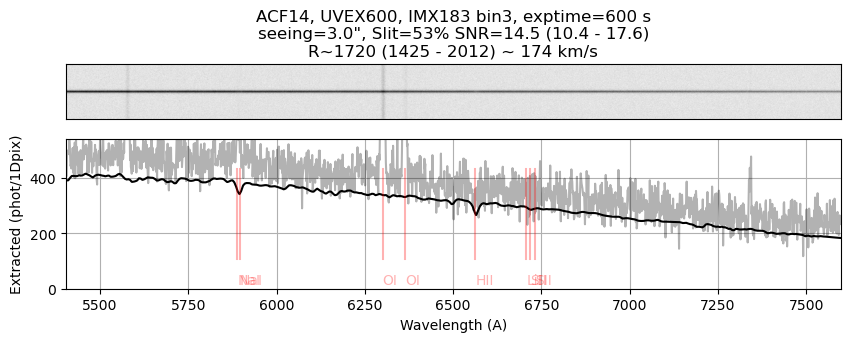

In [5]:
im, spec, var = SpecETC(star, sky, ACF14, UVEX600, IMX183, plot=True)

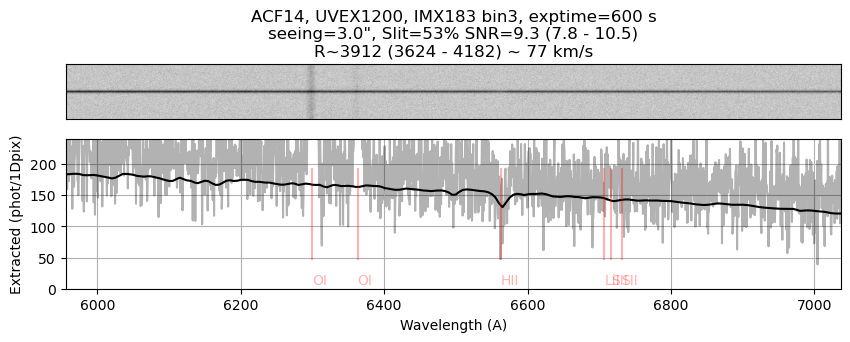

In [6]:
im, spec, var = SpecETC(star, sky, ACF14, UVEX1200, IMX183, plot=True)

In [7]:
def compare_instrumentation(instrumentation, sptype='G5V', mag=14):
    plt.figure(figsize=(12,4))
    plt.title(f'{sptype} star mag={mag:.1f}')
    peakSNR = 0
    wavmin = 3500
    wavmax = 8800
    for i,inst in enumerate(instrumentation):
        tel, spec, det, binning, exptime, deltam = inst
        det.exptime = exptime
        det.set_binning(binning)
        spec.set_detector(det)
        star = get_stellar_spectrum(sptype=sptype, mag=mag+deltam)
        # im, spectra, variance = SpecETC(star, sky, tel, spec, det, plot=False)
        spec.get_geometric_efficiency(tel)
        signal, skysignal, trace_profile, slit_throughput = simulate_1D_spectrum(
                                            star, sky, tel, spec, det, plot=False)
        im, spectra, variance = simulate_2D_spectrum(signal, skysignal, trace_profile,
                                            star, sky, tel, spec, det, plot=False)
        R = np.mean(spec.R)
        SNR = spectra/variance**0.5
        label = f"{tel.name}+{spec.name}+{det.name}@{det.exptime:.0f}: SNR={SNR.mean():.1f}, R~{R:.0f} (dm={deltam:+4.2f})"

        line = f"{tel.name:10s} {spec.name:10s} {det.name:11s}@{det.exptime:.0f}: "
        line += f"SNR={SNR.mean():.1f}, R~{R:.0f} (dm={deltam:+4.2f}) (Slit={slit_throughput:.0%})"
        print(line)
        plt.plot(spec.binset, SNR, alpha=0.5, label=label)
        peakSNR = peakSNR if max(SNR) <= peakSNR else max(SNR)
    
    lines_file = Path('.') / 'data' / 'spectral_lines.csv'
    lines = Table.read(lines_file, format='ascii.csv')
    for line in lines:
        if line['wav'] > wavmin and line['wav'] < wavmax:
            if line['wav'] < 5500:
                color = 'b'
                alpha = 0.3
            elif line['wav'] < 7000:
                color = 'orange'
                alpha = 0.5
            else:
                color = 'r'
                alpha = 0.4
            plt.axvline(line['wav'], ymin=0, ymax=0.9,
                        color=color, alpha=alpha)
            plt.text(line['wav'], 1.03*peakSNR, line['name'],
                     color=color, alpha=alpha)
    
    plt.ylabel('SNR')
    plt.xlabel('Wavelength (A)')
    plt.xlim(wavmin, wavmax)
    plt.ylim(0,1.2*peakSNR)
    plt.grid()
    plt.legend(loc='best')
    plt.show()

# Compare Telescopes

ACF14      UVEX300    IMX183 bin3@600 s: SNR=19.9, R~696 (dm=+0.00) (Slit=53%)
ACF14      UVEX300/35 IMX183 bin3@600 s: SNR=19.9, R~497 (dm=+0.25) (Slit=67%)
ACF14x0.63 UVEX300    IMX183 bin3@600 s: SNR=20.2, R~696 (dm=+0.35) (Slit=72%)
RCA10      UVEX300    IMX183 bin3@600 s: SNR=20.3, R~696 (dm=-0.30) (Slit=80%)
SVX152     UVEX300    IMX183 bin3@600 s: SNR=20.5, R~696 (dm=-0.95) (Slit=91%)
VYSOS20    UVEX300    IMX183 bin3@600 s: SNR=19.6, R~696 (dm=+0.70) (Slit=47%)
VYSOS20    UVEX300/35 IMX183 bin3@600 s: SNR=19.3, R~497 (dm=+1.00) (Slit=60%)


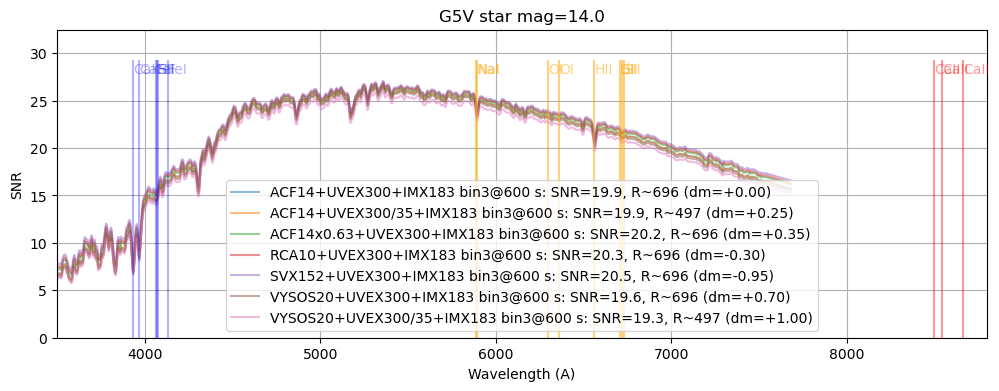

In [8]:
instrumentation = [(ACF14,        UVEX300,    IMX183, 3, 600*u.second, 0),
                   (ACF14,        UVEX300_35, IMX183, 3, 600*u.second, +0.25),
                   (ACF14reduced, UVEX300,    IMX183, 3, 600*u.second, +0.35),
                   (RCA10,        UVEX300,    IMX183, 3, 600*u.second, -0.30),
                   (SVX152,       UVEX300,    IMX183, 3, 600*u.second, -0.95),
                   (V20,          UVEX300,    IMX183, 3, 600*u.second, +0.70),
                   (V20,          UVEX300_35, IMX183, 3, 600*u.second, +1.00),
                   ]
compare_instrumentation(instrumentation)

ACF14      UVEX300    IMX183 bin3@600 s: SNR=20.1, R~696 (dm=+0.00) (Slit=53%)
ACF14      UVEX300/35 IMX183 bin3@600 s: SNR=20.1, R~497 (dm=+0.25) (Slit=67%)
ACF14x0.63 UVEX300    IMX183 bin3@600 s: SNR=20.4, R~696 (dm=+0.35) (Slit=72%)
RCA10      UVEX300    IMX183 bin3@600 s: SNR=20.5, R~696 (dm=-0.30) (Slit=80%)
SVX152     UVEX300    IMX183 bin3@600 s: SNR=20.7, R~696 (dm=-0.95) (Slit=91%)
VYSOS20    UVEX300    IMX183 bin3@600 s: SNR=19.9, R~696 (dm=+0.70) (Slit=47%)
VYSOS20    UVEX300/35 IMX183 bin3@600 s: SNR=19.6, R~497 (dm=+1.00) (Slit=60%)


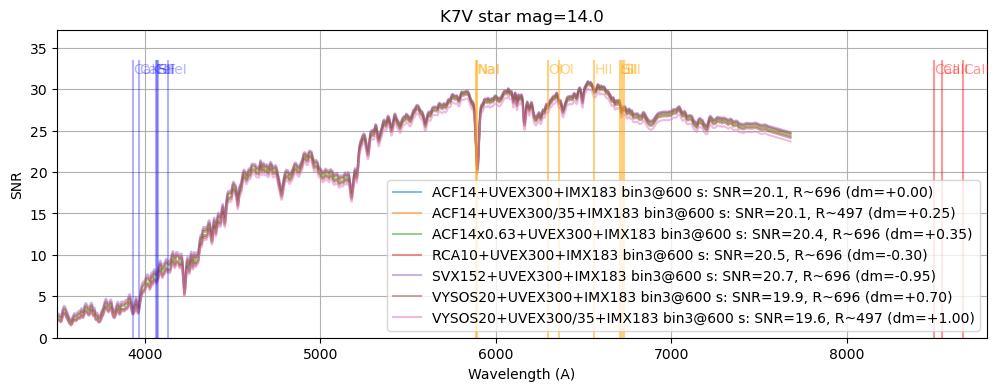

In [9]:
instrumentation = [(ACF14,        UVEX300,    IMX183, 3, 600*u.second, 0),
                   (ACF14,        UVEX300_35, IMX183, 3, 600*u.second, +0.25),
                   (ACF14reduced, UVEX300,    IMX183, 3, 600*u.second, +0.35),
                   (RCA10,        UVEX300,    IMX183, 3, 600*u.second, -0.30),
                   (SVX152,       UVEX300,    IMX183, 3, 600*u.second, -0.95),
                   (V20,          UVEX300,    IMX183, 3, 600*u.second, +0.70),
                   (V20,          UVEX300_35, IMX183, 3, 600*u.second, +1.00),
                   ]
compare_instrumentation(instrumentation, sptype='K7V', mag=14)

# Compare Detectors

ACF14      UVEX300    IMX533 bin2@600 s: SNR=22.9, R~696 (dm=+0.00) (Slit=53%)
ACF14      UVEX300    IMX183 bin3@600 s: SNR=21.0, R~696 (dm=-0.10) (Slit=53%)
VYSOS20    UVEX300    IMX533 bin2@600 s: SNR=22.8, R~696 (dm=+0.70) (Slit=46%)
VYSOS20    UVEX300    IMX183 bin3@600 s: SNR=20.8, R~696 (dm=+0.60) (Slit=47%)


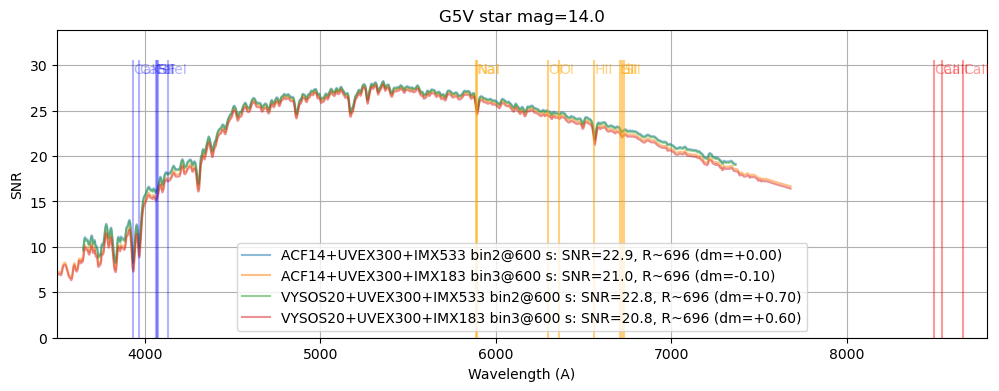

In [10]:
instrumentation = [(ACF14,  UVEX300, IMX533, 2, 600*u.second, 0),
                   (ACF14,  UVEX300, IMX183, 3, 600*u.second, -0.10),
                   (V20,    UVEX300, IMX533, 2, 600*u.second, +0.70),
                   (V20,    UVEX300, IMX183, 3, 600*u.second, +0.60),
                   ]
compare_instrumentation(instrumentation)

# Compare Spectrographs

ACF14      UVEX300    IMX183 bin3@600 s: SNR=20.1, R~696 (dm=+0.00) (Slit=53%)
ACF14      UVEX600    IMX183 bin3@600 s: SNR=27.5, R~1720 (dm=-0.75) (Slit=53%)
ACF14      UVEX1200   IMX183 bin3@600 s: SNR=28.0, R~3912 (dm=-1.50) (Slit=53%)


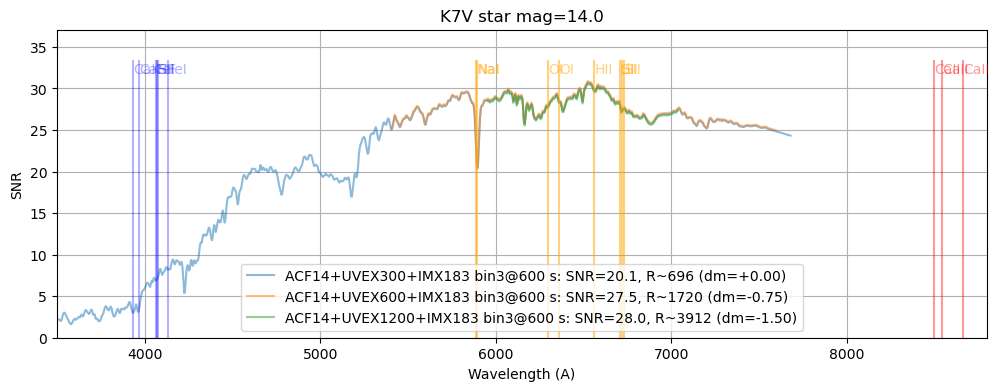

In [11]:
instrumentation = [(ACF14,        UVEX300,  IMX183, 3, 600*u.second, 0),
                   (ACF14,        UVEX600,  IMX183, 3, 600*u.second, -0.75),
                   (ACF14,        UVEX1200, IMX183, 3, 600*u.second, -1.50),
                   ]
compare_instrumentation(instrumentation, sptype='K7V', mag=14)